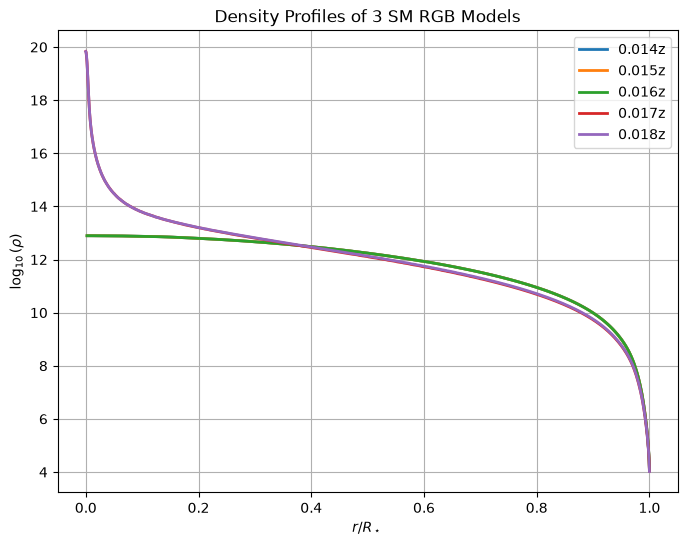

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.home() / "mesa_tutorial" / "results" / "mams_profiles"

models = [
    ("0.014z", ROOT / "RGB3Msun_Z0p0140"  / "RGB3Msun_Z0p0140.profile"),
    ("0.015z", ROOT / "RGB3Msun_Z0p0150"  / "RGB3Msun_Z0p0150.profile"),
    ("0.016z", ROOT / "RGB3Msun_Z0p0160"  / "RGB3Msun_Z0p0160.profile"),
    ("0.017z", ROOT / "RGB3Msun_Z0p0170"  / "RGB3Msun_Z0p0170.profile"),
    ("0.018z", ROOT / "RGB3Msun_Z0p0180"  / "RGB3Msun_Z0p0180.profile"),




]

plt.figure(figsize=(8,6))

for label, file in models:

    d = np.genfromtxt(file, names=True, skip_header=5)

    # Radius normalized to the stellar radius
    r = 10**d["logR"]
    r /= r.max()

    plt.plot(r, d["logP"], lw=2, label=label)

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\log_{10}(\rho)$")
plt.title(r"Density Profiles of 3 SM RGB Models")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# Your 3 Msun RGB models
# --------------------------------------------------

MODEL_DIR = Path(
    "/Users/mchau/mesa_tutorial/results/mams_profiles"
)

models = {
    0.0142:  MODEL_DIR / "RGB3Msun_Z0p0142/RGB3Msun_Z0p0142.mesa",
    0.015:  MODEL_DIR / "RGB3Msun_Z0p0150/RGB3Msun_Z0p0150.mesa",
    0.016:  MODEL_DIR / "RGB3Msun_Z0p0160/RGB3Msun_Z0p0160.mesa",
    0.017:  MODEL_DIR / "RGB3Msun_Z0p0170/RGB3Msun_Z0p0170.mesa",
    0.018:  MODEL_DIR / "RGB3Msun_Z0p0180/RGB3Msun_Z0p0180.mesa",
}


def read_mesa_model(path):
    """
    Read the MESA .mesa file used in your profiles.

    Header:
        nz, M_star, R_star, L_star, version

    Data columns:
        0 = index
        1 = radius
        2 = enclosed mass
        3 = luminosity
        4 = pressure
        5 = temperature
        6 = density
    """

    with open(path, "r") as f:
        header = f.readline().strip().split()
        data = np.loadtxt(f)

    nz = int(header[0])
    M_star = float(header[1])
    R_star = float(header[2])
    L_star = float(header[3])
    version = header[4]

    return {
        "nz": nz,
        "M_star": M_star,
        "R_star": R_star,
        "L_star": L_star,
        "version": version,
        "data": data,
    }

In [16]:
results = []

for Z, path in models.items():

    model = read_mesa_model(path)
    data = model["data"]

    # Columns from your MESA file
    radius = data[:, 1]
    mass = data[:, 2]
    temperature = data[:, 5]
    density = data[:, 6]

    # Fractional radius
    r_frac = radius / model["R_star"]

    results.append({
        "Z": Z,
        "N points": len(data),
        "Mstar (Msun)": model["M_star"] / 1.98847e33,
        "Rstar (Rsun)": model["R_star"] / 6.957e10,
        "Lstar (erg/s)": model["L_star"],

        # Central quantities
        "rho_c (g/cm3)": density[0],
        "log10(rho_c)": np.log10(density[0]),
        "T_c (K)": temperature[0],

        # Maximum density in the model
        "rho_max": np.max(density),
        "log10(rho_max)": np.log10(np.max(density)),
    })

df = pd.DataFrame(results)

print(df.to_string(index=False))

     Z  N points  Mstar (Msun)  Rstar (Rsun)  Lstar (erg/s)  rho_c (g/cm3)  log10(rho_c)      T_c (K)      rho_max  log10(rho_max)
0.0142       618      2.999909     10.180065   2.220881e+35       0.025709     -1.589913 2.252331e+06     0.025709       -1.589913
0.0150       615      2.999909     10.191201   2.202649e+35       0.025617     -1.591468 2.252848e+06     0.025617       -1.591468
0.0160       619      2.999909     10.192854   2.176540e+35       0.025594     -1.591855 2.255741e+06     0.025594       -1.591855
0.0170      1271      2.999909     10.221452   2.446215e+35   14508.116515      4.161611 6.388561e+07 14508.116515        4.161611
0.0180      1214      2.999909     10.127001   2.376058e+35   14471.907760      4.160526 6.359248e+07 14471.907760        4.160526


In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for Z, path in models.items():

    model = read_mesa_model(path)
    data = model["data"]

    r = data[:, 1]
    rho = data[:, 6]

    r_frac = r / model["R_star"]

    # Only show inner 10%
    mask = r_frac <= 0.10

    plt.plot(
        r_frac[mask],
        np.log10(rho[mask]),
        label=f"Z={Z}"
    )

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\log_{10}(\rho)$")
plt.title("Central density structure of 3 $M_\\odot$ RGB models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'RGB3Msun_Z0p0160/RGB3Msun_Z0p0160.profile'

<Figure size 800x500 with 0 Axes>

In [13]:
for Z, path in models.items():

    model = read_mesa_model(path)
    data = model["data"]

    print("\n" + "="*60)
    print(f"Z = {Z}")
    print(f"File = {path}")

    print(f"Number of points = {len(data)}")
    print(f"Mass = {model['M_star']/1.98847e33:.6f} Msun")
    print(f"Radius = {model['R_star']/6.957e10:.3f} Rsun")

    print("\nFirst model point:")
    print(data[0])

    print("\nLast model point:")
    print(data[-1])

    print("\nCentral:")
    print(f"rho = {data[0,6]:.6e} g/cm3")
    print(f"T   = {data[0,5]:.6e} K")


Z = 0.0142
File = /Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0142/RGB3Msun_Z0p0142.mesa
Number of points = 618
Mass = 2.999909 Msun
Radius = 10.180 Rsun

First model point:
[ 1.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  7.89428829e+12  2.25233074e+06  2.57091222e-02  3.61136213e-01
  0.00000000e+00  1.65275650e+00  3.89504648e-01  1.03836187e+00
  3.99244422e+00 -9.71343912e+00  2.88424824e+00  1.27457630e-08
  1.19404024e-07  1.28112280e-08  0.00000000e+00]

Last model point:
[6.18000000e+02 7.08227076e+11 5.96522961e+33 2.22088131e+35
 1.20660947e+04 4.99278709e+03 3.73454809e-08 1.25016224e-01
 5.26590891e-07 1.65324582e+00 3.94052613e-01 1.00372633e+00
 4.38631380e-02 1.28991872e-01 3.58573865e-02 1.00876591e-27
 4.73483549e-28 1.00895453e-27 0.00000000e+00]

Central:
rho = 2.570912e-02 g/cm3
T   = 2.252331e+06 K

Z = 0.015
File = /Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0150/RGB3Msun_Z0p0150.mesa
Number of points = 615
Mas

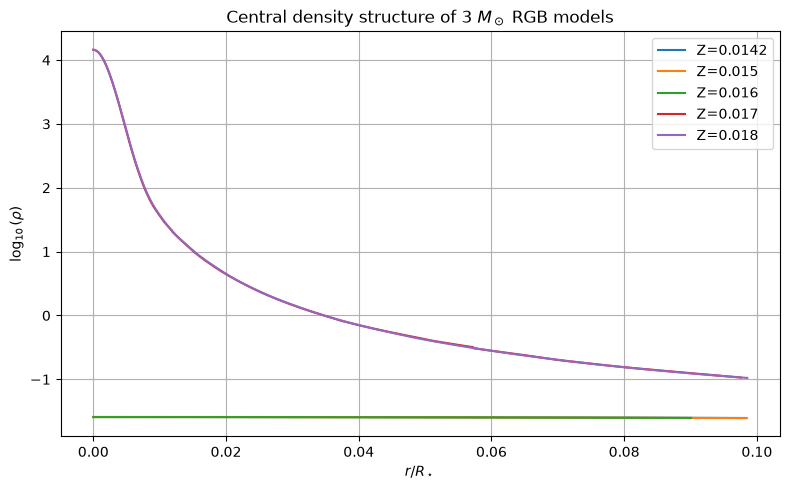

In [23]:
models = {
    0.0142: "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0142/RGB3Msun_Z0p0142.mesa",
    0.0150: "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0150/RGB3Msun_Z0p0150.mesa",
    0.0160: "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0160/RGB3Msun_Z0p0160.mesa",
    0.0170: "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0170/RGB3Msun_Z0p0170.mesa",
    0.0180: "/Users/mchau/mesa_tutorial/results/mams_profiles/RGB3Msun_Z0p0180/RGB3Msun_Z0p0180.mesa",
}

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for Z, path in models.items():

    model = read_mesa_model(path)
    data = model["data"]

    r = data[:, 1]
    rho = data[:, 6]

    r_frac = r / model["R_star"]

    # Inner 10% of stellar radius
    mask = r_frac <= 0.10

    plt.plot(
        r_frac[mask],
        np.log10(rho[mask]),
        label=f"Z={Z}"
    )

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\log_{10}(\rho)$")
plt.title(r"Central density structure of 3 $M_\odot$ RGB models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
for Z, path in models.items():

    model = read_mesa_model(path)
    data = model["data"]

    print(f"\nZ = {Z}")

    print(f"Radius = {model['R_star']/6.957e10:.3f} Rsun")
    print(f"Central T = {data[0,5]:.3e} K")
    print(f"Central rho = {data[0,6]:.3e} g/cm^3")
    print(f"Central H = {data[0,7]:.6f}")
    print(f"Central He = {data[0,10]:.6f}")


Z = 0.0142
Radius = 10.180 Rsun
Central T = 2.252e+06 K
Central rho = 2.571e-02 g/cm^3
Central H = 0.361136
Central He = 0.389505

Z = 0.015
Radius = 10.191 Rsun
Central T = 2.253e+06 K
Central rho = 2.562e-02 g/cm^3
Central H = 0.364259
Central He = 0.389433

Z = 0.016
Radius = 10.193 Rsun
Central T = 2.256e+06 K
Central rho = 2.559e-02 g/cm^3
Central H = 0.368292
Central He = 0.389347

Z = 0.017
Radius = 10.221 Rsun
Central T = 6.389e+07 K
Central rho = 1.451e+04 g/cm^3
Central H = 0.212873
Central He = 0.391261

Z = 0.018
Radius = 10.127 Rsun
Central T = 6.359e+07 K
Central rho = 1.447e+04 g/cm^3
Central H = 0.212887
Central He = 0.391272
